In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.all

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
def plot_maps_tele_delta(x, y, z, titles, labels, cmap, levels, pval = [], pval2=[], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        if pval2 != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval[i] <= 0.05, True, False)
            # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_tele_delta(x, y, z, title, label, cmap, levels, add_sign=False, pval = [],  pval2 = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        pval_plot = np.ma.masked_less_equal(pval, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        pval_plot = np.ma.masked_less_equal(pval2, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [13]:
import matplotlib.colors as mcolors

In [14]:
def plot_teleconnection_robustness(
    field,
    lon, lat,
    snr_model=None,
    snr_obs=None,
    pval_model=None,
    snr_threshold=1.5,
    pval_threshold=0.05,
    use_pval=False,
    valid_obs=None,                 # NEW: bool DataArray (lat,lon), True where CNR_obs is defined
    cmap='RdBu_r',
    vmin=None,
    vmax=None,
    title_main='',
    title_suffix='',
    cbar_label='',
    label_model='t-test only',
    label_obs='CNR$_{obs}$ only',
    label_both='Both',
    label_noobs='No obs. constraint',
):
    """
    Panel A: teleconnection change. Panel B: categorical robustness map.

    If `valid_obs` is supplied, gridpoints where the observational test is
    undefined (record too short) are NOT classified into the obs-dependent
    categories. Instead the model-only result is shown underneath and a hatch
    overlay flags that the observational comparison was unavailable there.
    """
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes
    from matplotlib.patches import Patch

    xx, yy = np.meshgrid(lon, lat)

    # --- Robustness masks ---
    if use_pval:
        mask_model = pval_model <= pval_threshold
        mask_obs   = np.abs(snr_obs) > snr_threshold if snr_obs is not None else None
    else:
        mask_model = np.abs(snr_model) > snr_threshold
        mask_obs   = np.abs(snr_obs)   > snr_threshold

    mask_both = mask_model & mask_obs if mask_obs is not None else mask_model

    # --- Valid-obs handling ---
    if valid_obs is not None:
        valid_v = valid_obs.values.astype(bool)
    else:
        valid_v = np.ones(xx.shape, dtype=bool)   # everything valid if not supplied
    no_obs_v = ~valid_v

    # --- Figure ---
    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )

    # ===========================
    # Panel A: signal field
    # ===========================
    im = axes[0].pcolormesh(
        xx, yy, field.values,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )
    cax = inset_axes(axes[0], width='70%', height='5%',
                     loc='lower center', borderpad=-2.5)
    plt.colorbar(im, cax=cax, orientation='horizontal', label=cbar_label)

    # Stippling — only where the full "both" classification is valid
    stip = mask_both.values & valid_v
    axes[0].scatter(
        xx[stip], yy[stip],
        s=2, color='k', marker='.',
        transform=ccrs.PlateCarree(), zorder=5
    )
    axes[0].set_title(title_main)
    plot_background(axes[0])

    # ===========================
    # Panel B: categorical map
    # ===========================
    if mask_obs is not None:
        mm = mask_model.values
        mo = mask_obs.values
        mb = mask_both.values

        # Four categories — only where obs is valid
        base       = np.where(~mm & ~mo & valid_v, 1, np.nan)
        model_only = np.where( mm & ~mo & valid_v, 1, np.nan)
        obs_only   = np.where(~mm &  mo & valid_v, 1, np.nan)
        both       = np.where( mb        & valid_v, 1, np.nan)

        # In the no-obs zone: show model result underneath (grey base + model-only blue)
        base_noobs  = np.where(~mm & no_obs_v, 1, np.nan)
        model_noobs = np.where( mm & no_obs_v, 1, np.nan)

        both_color = '#7B4F9E'

        # No-obs underlay first
        axes[1].pcolormesh(xx, yy, base_noobs,
                           cmap=mcolors.ListedColormap(['lightgrey']),
                           vmin=0, vmax=1,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, model_noobs,
                           cmap=mcolors.ListedColormap(['tab:blue']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())

        # Valid-obs categories
        axes[1].pcolormesh(xx, yy, base,
                           cmap=mcolors.ListedColormap(['lightgrey']),
                           vmin=0, vmax=1,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, model_only,
                           cmap=mcolors.ListedColormap(['tab:blue']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, obs_only,
                           cmap=mcolors.ListedColormap(['tab:orange']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, both,
                           cmap=mcolors.ListedColormap([both_color]),
                           vmin=0, vmax=1, alpha=0.8,
                           transform=ccrs.PlateCarree())

        # Hatch overlay marking the no-obs zone
        if no_obs_v.any():
            axes[1].contourf(xx, yy, no_obs_v.astype(float),
                             levels=[0.5, 1.5], colors='none',
                             hatches=['////'],
                             transform=ccrs.PlateCarree(), zorder=6)

        legend_elements = [
            Patch(facecolor='lightgrey',               label='Neither'),
            Patch(facecolor='tab:blue',   alpha=0.6,   label=label_model),
            Patch(facecolor='tab:orange', alpha=0.6,   label=label_obs),
            Patch(facecolor=both_color,   alpha=0.8,   label=label_both),
        ]
        if no_obs_v.any():
            legend_elements.append(
                Patch(facecolor='white', edgecolor='k', hatch='////',
                      label=label_noobs)
            )
    else:
        base   = np.where(~mask_both.values, 1, np.nan)
        robust = np.where( mask_both.values, 1, np.nan)

        axes[1].pcolormesh(xx, yy, base,
                           cmap=mcolors.ListedColormap(['lightgrey']),
                           vmin=0, vmax=1,
                           transform=ccrs.PlateCarree())
        axes[1].pcolormesh(xx, yy, robust,
                           cmap=mcolors.ListedColormap(['tab:red']),
                           vmin=0, vmax=1, alpha=0.6,
                           transform=ccrs.PlateCarree())

        legend_elements = [
            Patch(facecolor='lightgrey',           label='Not robust'),
            Patch(facecolor='tab:red', alpha=0.6,  label='Robust'),
        ]

    axes[1].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.0, -0.05),
                   ncol=2, fontsize=11, framealpha=0.7, columnspacing=1.2, handletextpad=0.5)
    axes[1].set_title(title_suffix)
    plot_background(axes[1])

    plt.tight_layout(rect=[0, 0.08, 1, 1])
    # return fig

In [15]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Patch

def plot_composite(field, lon, lat, vmin=-1.0, vmax=1.0,
                   cmap='RdBu_r', cbar_label='', title=''):
    
    xx, yy = np.meshgrid(lon, lat)
    
    fig, ax = plt.subplots(
        figsize=(8, 4),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )
    im = ax.pcolormesh(
        xx, yy, field.values,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )
    cax = inset_axes(ax, width='60%', height='5%',
                     loc='lower center', borderpad=-2.5)
    plt.colorbar(im, cax=cax, orientation='horizontal', label=cbar_label)
    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()
    # return fig


def plot_baseline_teleconnection(
    field,
    lon, lat,
    sig_data,
    mode='cmip6',
    p_threshold=0.05,
    agreement_threshold=0.8,
    cmap='RdBu_r',
    vmin=-1.0,
    vmax=1.0,
    cbar_label='',
    title='',
):
    xx, yy = np.meshgrid(lon, lat)

    fig, ax = plt.subplots(
        figsize=(8, 4),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )

    im = ax.pcolormesh(
        xx, yy, field.values,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )

    cax = inset_axes(ax, width='60%', height='5%',
                     loc='lower center', borderpad=-2.5)
    plt.colorbar(im, cax=cax, orientation='horizontal', label=cbar_label)

    # --- Agreement / significance ---
    sig = sig_data <= p_threshold
    if mode == 'cmip6':
        agreement = sig.mean('model')
    elif mode == 'smile':
        sig_stacked = sig.stack(ensemble=('model', 'smile'))
        agreement   = sig_stacked.mean('ensemble')
    else:
        raise ValueError("mode must be 'cmip6' or 'smile'")

    mask = agreement >= agreement_threshold
    ax.scatter(
        xx[mask.values], yy[mask.values],
        s=1, marker='.', color='k',
        transform=ccrs.PlateCarree(), zorder=5
    )

    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()
    # return fig

In [16]:
import sys

In [17]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [18]:
from functions import preproc_funcs as funcs

In [19]:
base_path = "/g/data/if69/as8561/data/enso_tele_robustness"

smile_models = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
]


In [20]:
from tqdm.auto import tqdm

In [21]:
clim_base = slice('1960', '1990')
baseline  = slice('1950', '2014')

In [22]:
# Load
tas_obs  = xr.open_dataset(f"{base_path}/tas_obs.nc").load()
pr_obs   = xr.open_dataset(f"{base_path}/pr_obs.nc").load()
pr_rean  = xr.open_dataset(f"{base_path}/pr_rean.nc").load()
nino34   = xr.open_dataset(f"{base_path}/nino34_index_hadisst.nc").load()
tas_cmip6 = xr.open_dataset(f"{base_path}/cmip6/ts_ssp5.nc").load()
pr_cmip6  = xr.open_dataset(f"{base_path}/cmip6/pr_ssp5.nc").load()

# Detrend obs/rean/cmip6 — already anomalised
tas_obs['ts']  = funcs.detrend_rolling_window(tas_obs['tas'],  window_size=15)
pr_obs['pr']    = funcs.detrend_rolling_window(pr_obs['pr'],    window_size=15)
pr_rean['pr']   = funcs.detrend_rolling_window(pr_rean['pr'],   window_size=15)
tas_cmip6['ts'] = funcs.detrend_rolling_window(tas_cmip6['ts'], window_size=15)
pr_cmip6['pr']  = funcs.detrend_rolling_window(pr_cmip6['pr'],  window_size=15)

# Standardise PR — per gridpoint std over full record
pr_obs['pr']   = pr_obs['pr']   / pr_obs['pr'].std('time')
pr_rean['pr']  = pr_rean['pr']  / pr_rean['pr'].std('time')
pr_cmip6['pr'] = pr_cmip6['pr'] / pr_cmip6['pr'].std('time')

# Detrend nino34 obs
nino34_obs = nino34.rename({'tos': 'ts'})
nino34_obs['ts'] = funcs.detrend_rolling_window(nino34_obs['ts'], window_size=15)

In [23]:
tas_smile, pr_smile, nino34_smile = {}, {}, {}

nino34_lat = slice(-5, 5)
nino34_lon = slice(190, 240)

for m in tqdm(smile_models, desc='Loading and processing SMILEs'):
    # Load
    ts = xr.open_dataset(f"{base_path}/smiles/{m}_ts.nc", decode_times=False)
    pr = xr.open_dataset(f"{base_path}/smiles/{m}_pr.nc", decode_times=False)
    ts = xr.decode_cf(ts).convert_calendar('standard', use_cftime=False).load()
    pr = xr.decode_cf(pr).convert_calendar('standard', use_cftime=False).load()

    # Rename tas to ts
    ts = ts.rename({list(ts.data_vars)[0]: 'ts'})
    pr = pr.rename({list(pr.data_vars)[0]: 'pr'})

    # Anomaly + detrend
    ts['ts'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(ts['ts'], ts['ts'].sel(time=clim_base)),
        window_size=15
    )
    pr['pr'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(pr['pr'], pr['pr'].sel(time=clim_base)),
        window_size=15
    )

    # Standardise PR
    pr['pr'] = pr['pr'] / pr['pr'].std('time')

    # Nino3.4 index
    nino34_smile[m] = ts['ts'].sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])

    tas_smile[m] = ts
    pr_smile[m]  = pr

Loading and processing SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [24]:
import xesmf as xe

# --- Build regridders once using full fields as template ---
regridder_pr_rean = xe.Regridder(pr_rean,  tas_obs, 'bilinear',
                                  periodic=True, ignore_degenerate=True)
# regridder_tas_obs = xe.Regridder(tas_obs,  tas_cmip6, 'bilinear',
#                                   periodic=True, ignore_degenerate=True)
# regridder_pr_obs  = xe.Regridder(pr_obs,   tas_cmip6, 'bilinear',
#                                   periodic=True, ignore_degenerate=True)

# # --- Regrid ---
pr_rean_regrid = regridder_pr_rean(pr_rean['pr'])
# tas_obs_regrid = regridder_tas_obs(tas_obs['tas'])
# pr_obs_regrid  = regridder_pr_obs(pr_obs['pr'])

# Regrid CMIP6 to SMILE grid
regridder_cmip6_to_smile = xe.Regridder(
    tas_cmip6, tas_smile['ACCESS-ESM1-5'],
    'bilinear', periodic=True, ignore_degenerate=True
)

tas_cmip6_regrid = regridder_cmip6_to_smile(tas_cmip6['ts'])
pr_cmip6_regrid  = regridder_cmip6_to_smile(pr_cmip6['pr'])
nino34_cmip6     = tas_cmip6_regrid.sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])

In [25]:
pr_rean_regrid

<xarray.DataArray (time: 181, lat: 72, lon: 144)> Size: 8MB
array([[[ 0.3598478 ,  0.34797767,  0.34928456, ...,  0.37918818,
          0.38093185,  0.36273336],
        [ 0.37898543,  0.39309812,  0.41411024, ...,  0.3535402 ,
          0.3612698 ,  0.3847404 ],
        [ 0.34550008,  0.3558439 ,  0.35201535, ...,  0.2954949 ,
          0.32829264,  0.3409277 ],
        ...,
        [-0.40988255, -0.41222587, -0.4240365 , ..., -0.3798572 ,
         -0.39730898, -0.4064333 ],
        [-0.388088  , -0.39358154, -0.3911582 , ..., -0.3787509 ,
         -0.38313353, -0.3853692 ],
        [-0.22181426, -0.2213839 , -0.22094682, ..., -0.22235416,
         -0.22337967, -0.22152917]],

       [[-0.56796396, -0.5431723 , -0.5554851 , ..., -0.56339395,
         -0.5753078 , -0.56396216],
        [-0.5931369 , -0.58673704, -0.5907908 , ..., -0.5399094 ,
         -0.5640921 , -0.59048104],
        [-0.37084562, -0.36873198, -0.36960927, ..., -0.39381406,
         -0.41119027, -0.39075944],
...
        [ 1.3625195 ,  1.1929013 ,  1.0756799 , ...,  1.8504353 ,
          1.7269614 ,  1.5329543 ],
        [ 1.3530098 ,  1.2958316 ,  1.2485662 , ...,  1.6400398 ,
          1.5386264 ,  1.4314213 ],
        [ 2.8510206 ,  2.8559937 ,  2.8578763 , ...,  2.8208582 ,
          2.832551  ,  2.845463  ]],

       [[ 0.17249925,  0.16008304,  0.14311084, ...,  0.19201376,
          0.18524432,  0.18453076],
        [ 1.1721916 ,  1.1426617 ,  1.1032087 , ...,  1.2093097 ,
          1.1942762 ,  1.1888198 ],
        [ 1.5965018 ,  1.5576457 ,  1.505671  , ...,  1.6254972 ,
          1.609916  ,  1.601075  ],
        ...,
        [ 0.39486834,  0.44444633,  0.47263065, ...,  0.00663859,
          0.18204962,  0.30779436],
        [ 0.08290421,  0.11693346,  0.15213625, ..., -0.11007354,
         -0.04333578,  0.03079221],
        [-1.335353  , -1.3357791 , -1.3382668 , ..., -1.3281664 ,
         -1.3281779 , -1.3320404 ]]], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 1kB 1835-06-01 1836-06-01 ... 2015-06-01
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
Attributes:
    regrid_method:  bilinear

In [26]:
nino34_cmip6 = tas_cmip6['ts'].sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])

# Thresholds from baseline
obs_std   = float(nino34_obs['ts'].sel(time=baseline).std('time'))
cmip6_std = nino34_cmip6.sel(time=baseline).std('time')   # (model,)

# Obs masks
cond_en_obs  = nino34_obs['ts'] >  0.5 * obs_std
cond_ln_obs  = nino34_obs['ts'] < -0.5 * obs_std
cond_neu_obs = (nino34_obs['ts'] >= -0.25 * obs_std) & \
               (nino34_obs['ts'] <= 0.25 * obs_std)

# CMIP6 masks — per model
cond_en_cmip6  = nino34_cmip6 >  0.5 * cmip6_std
cond_ln_cmip6  = nino34_cmip6 < -0.5 * cmip6_std
cond_neu_cmip6 = (nino34_cmip6 >= -0.25 * cmip6_std) & \
                 (nino34_cmip6 <=  0.25 * cmip6_std)

# SMILE masks — per member
cond_en_smile, cond_ln_smile, cond_neu_smile = {}, {}, {}
for m in smile_models:
    smile_std         = nino34_smile[m].sel(time=baseline).std('time')
    cond_en_smile[m]  = nino34_smile[m] >  0.5 * smile_std
    cond_ln_smile[m]  = nino34_smile[m] < -0.5 * smile_std
    cond_neu_smile[m] = (nino34_smile[m] >= -0.25 * smile_std) & \
                        (nino34_smile[m] <=  0.25 * smile_std)

print(f"Obs EN years:  {int(cond_en_obs.sum())}")
print(f"Obs LN years:  {int(cond_ln_obs.sum())}")
print(f"CMIP6 EN per model (mean): {float(cond_en_cmip6.sum('time').mean()):.1f}")

Obs EN years:  32
Obs LN years:  35
CMIP6 EN per model (mean): 77.4


In [27]:
def make_composites(da, cond_en, cond_ln, cond_neu):
    """
    Returns EN, LN, NEU composite means.
    Handles NaN years cleanly.
    """
    en  = da.where(cond_en).mean( 'time', skipna=True)
    ln  = da.where(cond_ln).mean( 'time', skipna=True)
    neu = da.where(cond_neu).mean('time', skipna=True)
    return en, ln, neu

# Obs baseline composites — on CMIP6 grid now
tas_en_obs, tas_ln_obs, tas_neu_obs = make_composites(
    tas_obs.sel(time=baseline),
    cond_en_obs.sel(time=baseline),
    cond_ln_obs.sel(time=baseline),
    cond_neu_obs.sel(time=baseline)
)
pr_en_rean, pr_ln_rean, pr_neu_rean = make_composites(
    pr_rean_regrid.sel(time=baseline),
    cond_en_obs.sel(time=baseline),
    cond_ln_obs.sel(time=baseline),
    cond_neu_obs.sel(time=baseline)
)

# CMIP6 baseline composites
tas_en_cmip6_base, tas_ln_cmip6_base, tas_neu_cmip6_base = make_composites(
    tas_cmip6_regrid.sel(time=baseline),
    cond_en_cmip6.sel(time=baseline),
    cond_ln_cmip6.sel(time=baseline),
    cond_neu_cmip6.sel(time=baseline)
)
pr_en_cmip6_base, pr_ln_cmip6_base, pr_neu_cmip6_base = make_composites(
    pr_cmip6_regrid.sel(time=baseline),
    cond_en_cmip6.sel(time=baseline),
    cond_ln_cmip6.sel(time=baseline),
    cond_neu_cmip6.sel(time=baseline)
)

In [28]:
# # --- Obs MW test ---
# pval_en_obs_tas = funcs.mannwhitneyu3d(
#     tas_obs.sel(time=baseline).where(cond_en_obs.sel(time=baseline),  drop=True),
#     tas_obs.sel(time=baseline).where(cond_neu_obs.sel(time=baseline), drop=True),
#     dim='time'
# )
# print('done')
# pval_ln_obs_tas = funcs.mannwhitneyu3d(
#     tas_obs.sel(time=baseline).where(cond_ln_obs.sel(time=baseline),  drop=True),
#     tas_obs.sel(time=baseline).where(cond_neu_obs.sel(time=baseline), drop=True),
#     dim='time'
# )
# print('done')
# pval_en_obs_pr = funcs.mannwhitneyu3d(
#     pr_rean.sel(time=baseline).where(cond_en_obs.sel(time=baseline),  drop=True),
#     pr_rean.sel(time=baseline).where(cond_neu_obs.sel(time=baseline), drop=True),
#     dim='time'
# )
# print('done')
# pval_ln_obs_pr = funcs.mannwhitneyu3d(
#     pr_rean.sel(time=baseline).where(cond_ln_obs.sel(time=baseline),  drop=True),
#     pr_rean.sel(time=baseline).where(cond_neu_obs.sel(time=baseline), drop=True),
#     dim='time'
# )
# print('done')

# # --- CMIP6 MW test — per model ---
# pval_en_cmip6_tas = funcs.mannwhitneyu3d(
#     tas_cmip6['ts'].sel(time=baseline).where(cond_en_cmip6.sel(time=baseline)),
#     tas_cmip6['ts'].sel(time=baseline).where(cond_neu_cmip6.sel(time=baseline)),
#     dim='time'
# )
# pval_ln_cmip6_tas = funcs.mannwhitneyu3d(
#     tas_cmip6['ts'].sel(time=baseline).where(cond_ln_cmip6.sel(time=baseline)),
#     tas_cmip6['ts'].sel(time=baseline).where(cond_neu_cmip6.sel(time=baseline)),
#     dim='time'
# )
# pval_en_cmip6_pr = funcs.mannwhitneyu3d(
#     pr_cmip6['pr'].sel(time=baseline).where(cond_en_cmip6.sel(time=baseline)),
#     pr_cmip6['pr'].sel(time=baseline).where(cond_neu_cmip6.sel(time=baseline)),
#     dim='time'
# )
# pval_ln_cmip6_pr = funcs.mannwhitneyu3d(
#     pr_cmip6['pr'].sel(time=baseline).where(cond_ln_cmip6.sel(time=baseline)),
#     pr_cmip6['pr'].sel(time=baseline).where(cond_neu_cmip6.sel(time=baseline)),
#     dim='time'
# )

In [29]:
# def plot_composite(field, lon, lat, vmin=-1.0, vmax=1.0,
#                    cmap='RdBu_r', cbar_label='', title=''):
#     fig = plt.figure(figsize=(8, 4))
#     ax  = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    
#     field.plot(
#         ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
#         cbar_kwargs=dict(orientation='horizontal', shrink=0.6,
#                          aspect=40, pad=0.05, label=cbar_label),
#         transform=ccrs.PlateCarree()
#     )
#     ax.set_title(title)
#     plot_background(ax)
#     plt.tight_layout()

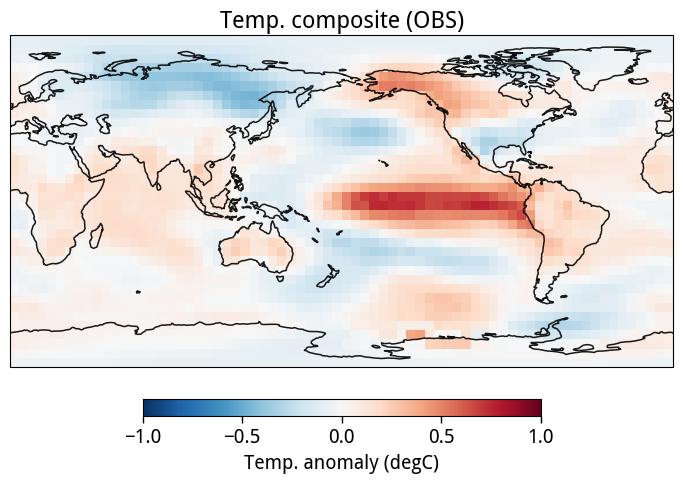

In [30]:
# obs MMM baseline composites
plot_composite(tas_en_obs.ts, 
               tas_obs.lon.values, tas_obs.lat.values,
               cmap='RdBu_r', cbar_label='Temp. anomaly (degC)', vmin=-1,
               title='Temp. composite (OBS)')


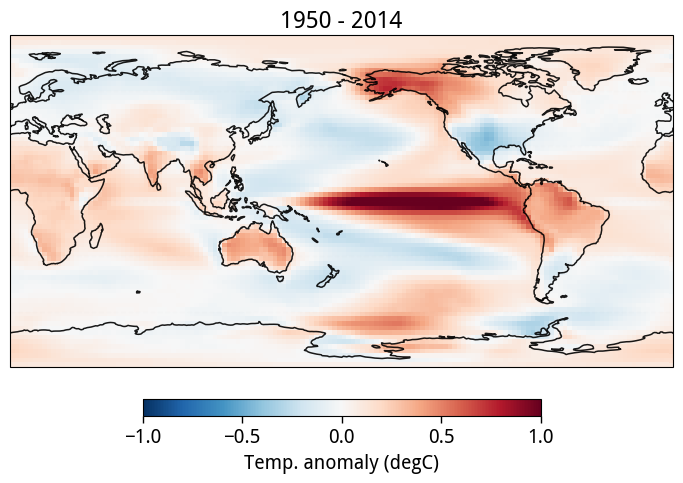

In [31]:
# CMIP6 MMM baseline composites
plot_composite(tas_en_cmip6_base.mean('model'), 
               tas_en_cmip6_base.lon.values, tas_en_cmip6_base.lat.values,
               cmap='RdBu_r', cbar_label='Temp. anomaly (degC)',
               title='1950 - 2014')


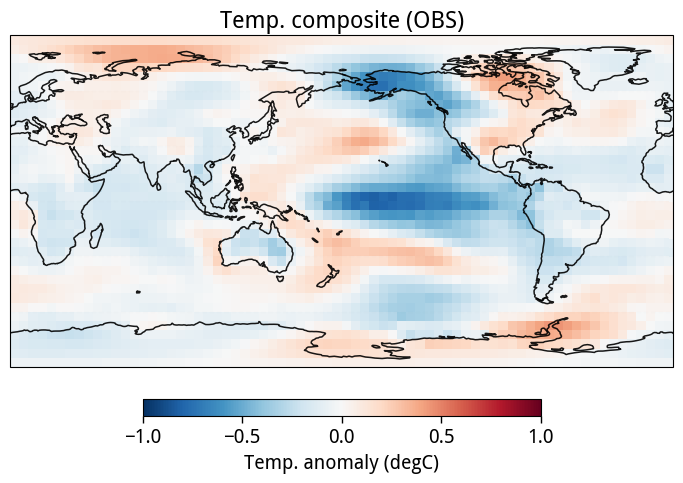

In [32]:
# obs MMM baseline composites
plot_composite(tas_ln_obs.ts, 
               tas_obs.lon.values, tas_obs.lat.values,
               cmap='RdBu_r', cbar_label='Temp. anomaly (degC)',
               title='Temp. composite (OBS)')


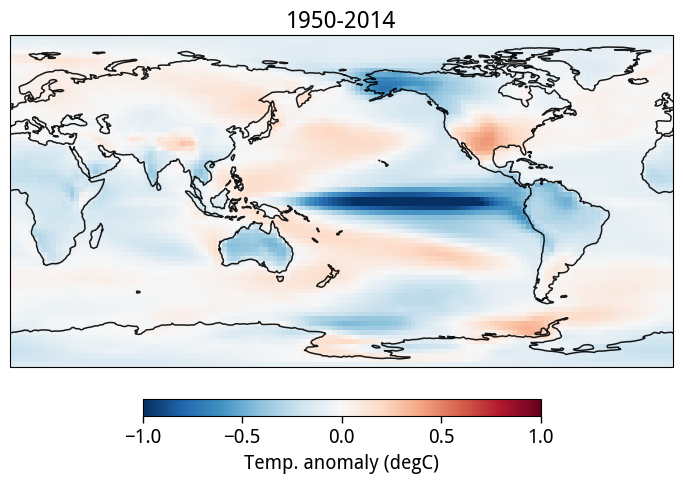

In [33]:
plot_composite(tas_ln_cmip6_base.mean('model'),
               tas_ln_cmip6_base.lon.values, tas_en_cmip6_base.lat.values,
               cmap='RdBu_r', cbar_label='Temp. anomaly (degC)',
               title='1950-2014')


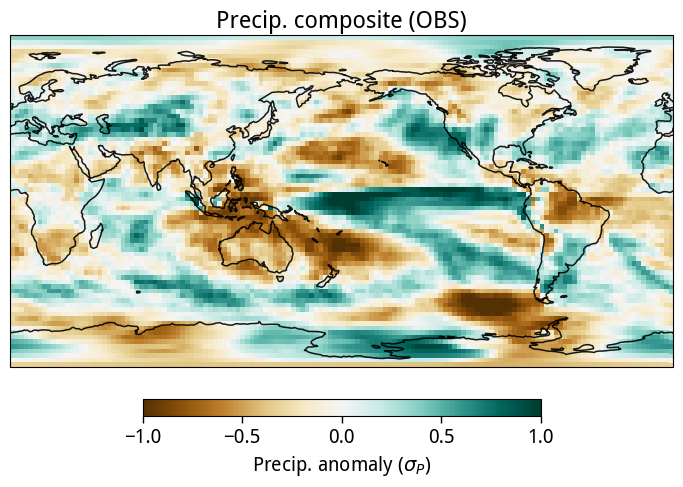

In [34]:
# rean MMM baseline composites
plot_composite(pr_en_rean, 
               pr_rean_regrid.lon.values, pr_rean_regrid.lat.values,
               cmap='BrBG', cbar_label='Precip. anomaly ($\sigma_{P}$)', vmin=-1,
               title='Precip. composite (OBS)')


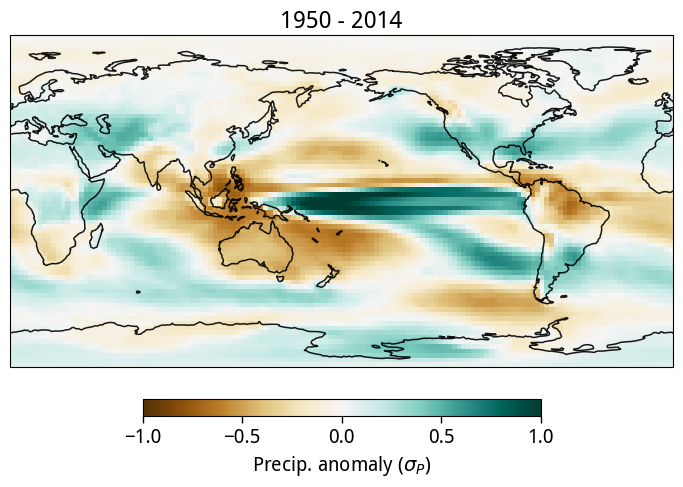

In [35]:
# CMIP6 MMM baseline composites
plot_composite(pr_en_cmip6_base.mean('model'), 
               pr_en_cmip6_base.lon.values, pr_en_cmip6_base.lat.values,
               cmap='BrBG', cbar_label='Precip. anomaly ($\sigma_{P}$)',
               title='1950 - 2014')


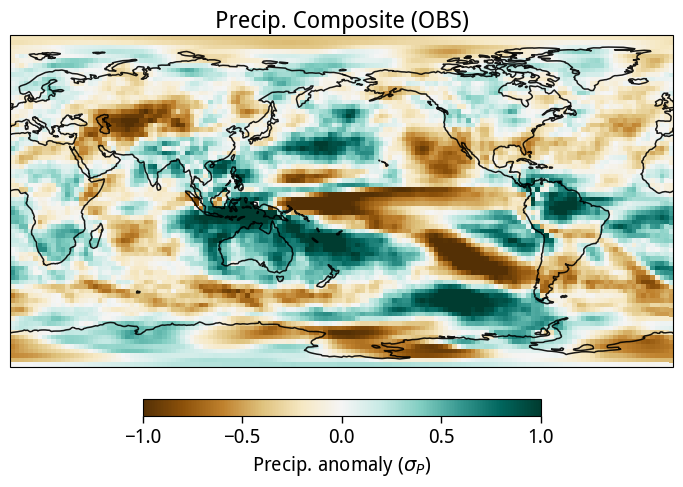

In [36]:
# rean MMM baseline composites
plot_composite(pr_ln_rean, 
               pr_rean_regrid.lon.values, pr_rean_regrid.lat.values,
               cmap='BrBG', cbar_label='Precip. anomaly ($\sigma_{P}$)',
               title='Precip. Composite (OBS)')


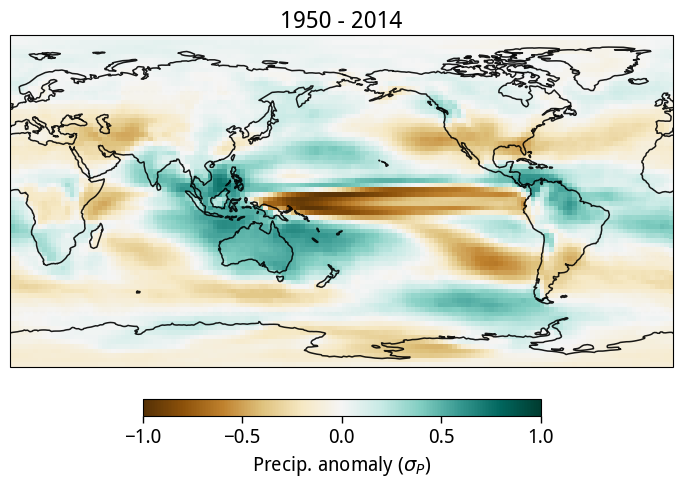

In [37]:
plot_composite(pr_ln_cmip6_base.mean('model'),
               pr_ln_cmip6_base.lon.values, pr_ln_cmip6_base.lat.values,
               cmap='BrBG', cbar_label='Precip. anomaly ($\sigma_{P}$)',
               title='1950 - 2014')


In [38]:
fut = slice('2070', '2100')

# --- CMIP6 future composites ---
tas_en_cmip6_fut, tas_ln_cmip6_fut, _ = make_composites(
    tas_cmip6_regrid.sel(time=fut),
    cond_en_cmip6.sel(time=fut),
    cond_ln_cmip6.sel(time=fut),
    cond_neu_cmip6.sel(time=fut)
)
pr_en_cmip6_fut, pr_ln_cmip6_fut, _ = make_composites(
    pr_cmip6_regrid.sel(time=fut),
    cond_en_cmip6.sel(time=fut),
    cond_ln_cmip6.sel(time=fut),
    cond_neu_cmip6.sel(time=fut)
)

# --- Signal = future minus baseline MMM ---
signal_en_tas = (tas_en_cmip6_fut - tas_en_cmip6_base).mean('model')
signal_ln_tas = (tas_ln_cmip6_fut - tas_ln_cmip6_base).mean('model')
signal_en_pr  = (pr_en_cmip6_fut  - pr_en_cmip6_base).mean('model')
signal_ln_pr  = (pr_ln_cmip6_fut  - pr_ln_cmip6_base).mean('model')

In [39]:
def ttest_ind1d(a, b):
    _, p = stats.ttest_ind(a,b, equal_var=False)
    return p


def ttest_ind3d(da1, da2, dim='model'):
    return xr.apply_ufunc(ttest_ind1d, da1, da2, input_core_dims=[[dim], [dim]], exclude_dims={dim, dim}, vectorize=True, dask='parallelized')

In [40]:
pval_en_tas_ttest = ttest_ind3d(tas_en_cmip6_fut, tas_en_cmip6_base, dim='model')
pval_ln_tas_ttest = ttest_ind3d(tas_ln_cmip6_fut, tas_ln_cmip6_base, dim='model')
pval_en_pr_ttest  = ttest_ind3d(pr_en_cmip6_fut,  pr_en_cmip6_base,  dim='model')
pval_ln_pr_ttest  = ttest_ind3d(pr_ln_cmip6_fut,  pr_ln_cmip6_base,  dim='model')

In [41]:
# # --- Obs rolling 30-year composite std as noise ---
# def obs_rolling_std(da, cond_en, cond_ln,
#                     start=1900, end=2014, duration=30, gap=1):
#     en_means, ln_means = [], []
#     for yr in range(start, end - duration + 2, gap):
#         win    = slice(str(yr), str(yr + duration - 1))
#         en_sub = da.sel(time=win).where(cond_en.sel(time=win), drop=True)
#         ln_sub = da.sel(time=win).where(cond_ln.sel(time=win), drop=True)
#         if en_sub.sizes['time'] > 2:
#             en_means.append(en_sub.mean('time', skipna=True))
#         if ln_sub.sizes['time'] > 2:
#             ln_means.append(ln_sub.mean('time', skipna=True))
#     en_std = xr.concat(en_means, dim='window').std('window')
#     ln_std = xr.concat(ln_means, dim='window').std('window')
#     return en_std, ln_std

# print("Computing obs rolling std for TAS...")
# noise_en_tas_obs, noise_ln_tas_obs = obs_rolling_std(
#     tas_obs.ts, cond_en_obs, cond_ln_obs)

# print("Computing obs rolling std for PR...")
# noise_en_pr_obs, noise_ln_pr_obs = obs_rolling_std(
#     pr_rean_regrid, cond_en_obs, cond_ln_obs)



def obs_composite_bootstrap(da, cond_en, cond_ln,
                            duration=30, block=3, n_boot=1000,
                            seed=0, min_years=60):
    rng = np.random.default_rng(seed)

    # --- Align field and conditions on a common time axis ---
    da, cond_en, cond_ln = xr.align(da, cond_en, cond_ln, join="inner")

    da   = da.transpose("time", "lat", "lon")
    da_v = da.values
    en_v = cond_en.values.astype(bool)
    ln_v = cond_ln.values.astype(bool)

    nt, nlat, nlon = da_v.shape
    n_blocks  = int(np.ceil(duration / block))
    max_start = nt - block

    valid_count = np.isfinite(da_v).sum(axis=0)
    valid_mask  = valid_count >= min_years

    en_boot = np.full((n_boot, nlat, nlon), np.nan)
    ln_boot = np.full((n_boot, nlat, nlon), np.nan)

    for b in tqdm(range(n_boot), desc="Composite bootstrap"):
        starts = rng.integers(0, max_start + 1, size=n_blocks)
        idx    = np.concatenate([np.arange(s, s + block) for s in starts])
        idx    = idx[:duration]

        sub    = da_v[idx]
        en_sel = en_v[idx]
        ln_sel = ln_v[idx]

        if en_sel.sum() >= 2:
            en_boot[b] = np.nanmean(sub[en_sel], axis=0)
        if ln_sel.sum() >= 2:
            ln_boot[b] = np.nanmean(sub[ln_sel], axis=0)

    en_std = np.nanstd(en_boot, axis=0, ddof=1)
    ln_std = np.nanstd(ln_boot, axis=0, ddof=1)

    coords   = dict(lat=da.lat, lon=da.lon)
    mask_da  = xr.DataArray(valid_mask, dims=["lat", "lon"], coords=coords)
    en_std   = xr.DataArray(en_std, dims=["lat", "lon"], coords=coords).where(mask_da)
    ln_std   = xr.DataArray(ln_std, dims=["lat", "lon"], coords=coords).where(mask_da)

    return en_std, ln_std, mask_da

In [42]:
print("Computing composite bootstrap noise for TAS...")
noise_en_tas_obs, noise_ln_tas_obs, valid_tas = obs_composite_bootstrap(
    tas_obs.ts, cond_en_obs, cond_ln_obs, block=3, n_boot=1000)

print("Computing composite bootstrap noise for PR...")
noise_en_pr_obs, noise_ln_pr_obs, valid_pr = obs_composite_bootstrap(
    pr_rean_regrid, cond_en_obs, cond_ln_obs, block=3, n_boot=1000)

Computing composite bootstrap noise for TAS...


Composite bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

Computing composite bootstrap noise for PR...


Composite bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

In [43]:
print("TAS EN composite noise — grid median:",
      float(noise_en_tas_obs.median()))
print("Valid gridpoints:", int(valid_tas.sum()), "of", valid_tas.size)

TAS EN composite noise — grid median: 0.11688986343222407
Valid gridpoints: 9232 of 10368


In [44]:
# --- SMILE IV ---
en_iv_tas_list, ln_iv_tas_list = [], []
en_iv_pr_list,  ln_iv_pr_list  = [], []

for m in tqdm(smile_models, desc='SMILE IV'):
    en_base_sm, ln_base_sm, _ = make_composites(
        tas_smile[m]['ts'].sel(time=baseline),
        cond_en_smile[m].sel(time=baseline),
        cond_ln_smile[m].sel(time=baseline),
        cond_neu_smile[m].sel(time=baseline)
    )
    en_iv_tas_list.append(en_base_sm.std('model'))
    ln_iv_tas_list.append(ln_base_sm.std('model'))

    en_base_pr, ln_base_pr, _ = make_composites(
        pr_smile[m]['pr'].sel(time=baseline),
        cond_en_smile[m].sel(time=baseline),
        cond_ln_smile[m].sel(time=baseline),
        cond_neu_smile[m].sel(time=baseline)
    )
    en_iv_pr_list.append(en_base_pr.std('model'))
    ln_iv_pr_list.append(ln_base_pr.std('model'))

# Average IV across SMILE models
iv_en_tas = xr.concat(en_iv_tas_list, dim='smile', coords='minimal').mean('smile')
iv_ln_tas = xr.concat(ln_iv_tas_list, dim='smile', coords='minimal').mean('smile')
iv_en_pr  = xr.concat(en_iv_pr_list,  dim='smile', coords='minimal').mean('smile')
iv_ln_pr  = xr.concat(ln_iv_pr_list,  dim='smile', coords='minimal').mean('smile')

SMILE IV:   0%|          | 0/10 [00:00<?, ?it/s]

In [45]:
# --- SNR ---
snr_en_tas_obs = signal_en_tas / noise_en_tas_obs
snr_ln_tas_obs = signal_ln_tas / noise_ln_tas_obs
snr_en_pr_obs  = signal_en_pr.drop('height')  / noise_en_pr_obs
snr_ln_pr_obs  = signal_ln_pr.drop('height')  / noise_ln_pr_obs

snr_en_tas_iv  = signal_en_tas / iv_en_tas
snr_ln_tas_iv  = signal_ln_tas / iv_ln_tas
snr_en_pr_iv   = signal_en_pr  / iv_en_pr
snr_ln_pr_iv   = signal_ln_pr  / iv_ln_pr

# --- Masks ---
threshold = 1.5

mask_en_tas_ttest = pval_en_tas_ttest < 0.05
mask_ln_tas_ttest = pval_ln_tas_ttest < 0.05
mask_en_pr_ttest  = pval_en_pr_ttest  < 0.05
mask_ln_pr_ttest  = pval_ln_pr_ttest  < 0.05

mask_en_tas_obs   = np.abs(snr_en_tas_obs) > threshold
mask_ln_tas_obs   = np.abs(snr_ln_tas_obs) > threshold
mask_en_pr_obs    = np.abs(snr_en_pr_obs)  > threshold
mask_ln_pr_obs    = np.abs(snr_ln_pr_obs)  > threshold

mask_en_tas_iv    = np.abs(snr_en_tas_iv)  > threshold
mask_ln_tas_iv    = np.abs(snr_ln_tas_iv)  > threshold
mask_en_pr_iv     = np.abs(snr_en_pr_iv)  > threshold
mask_ln_pr_iv     = np.abs(snr_ln_pr_iv)   > threshold

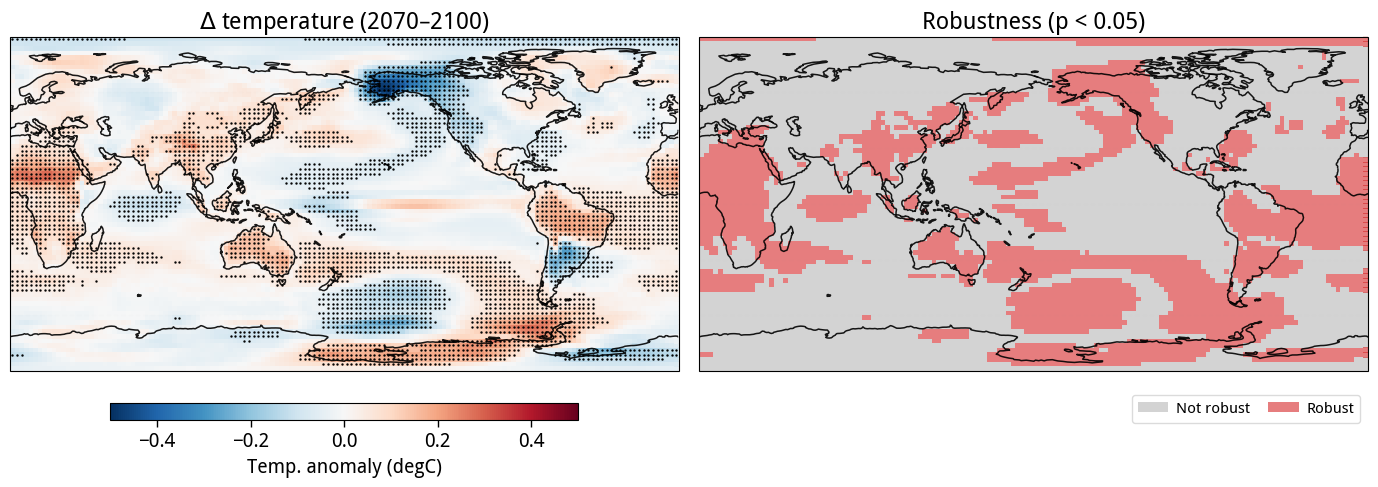

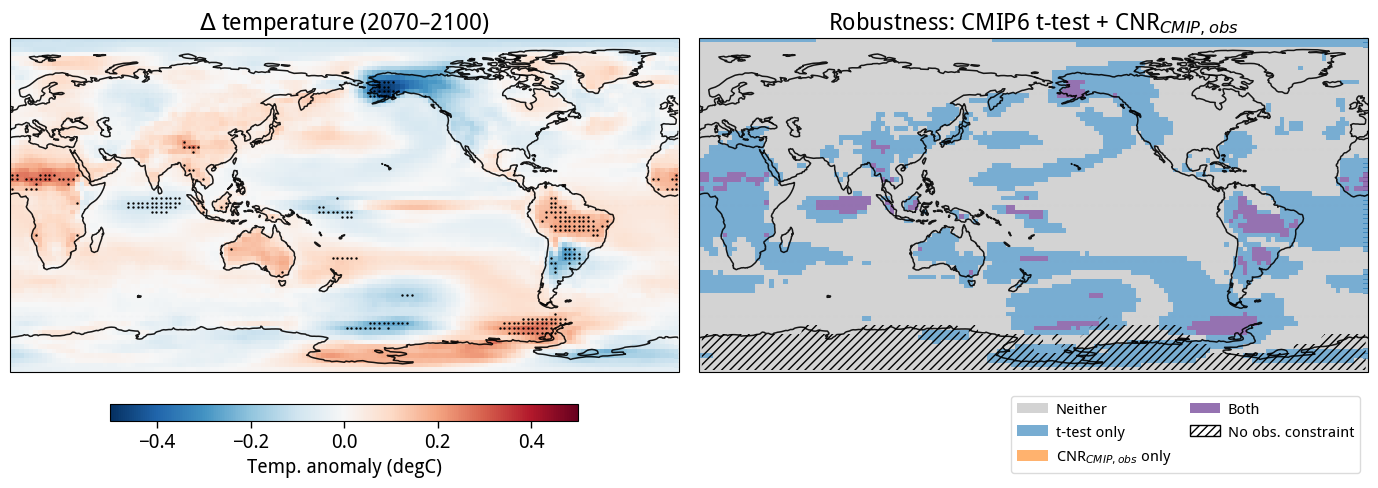

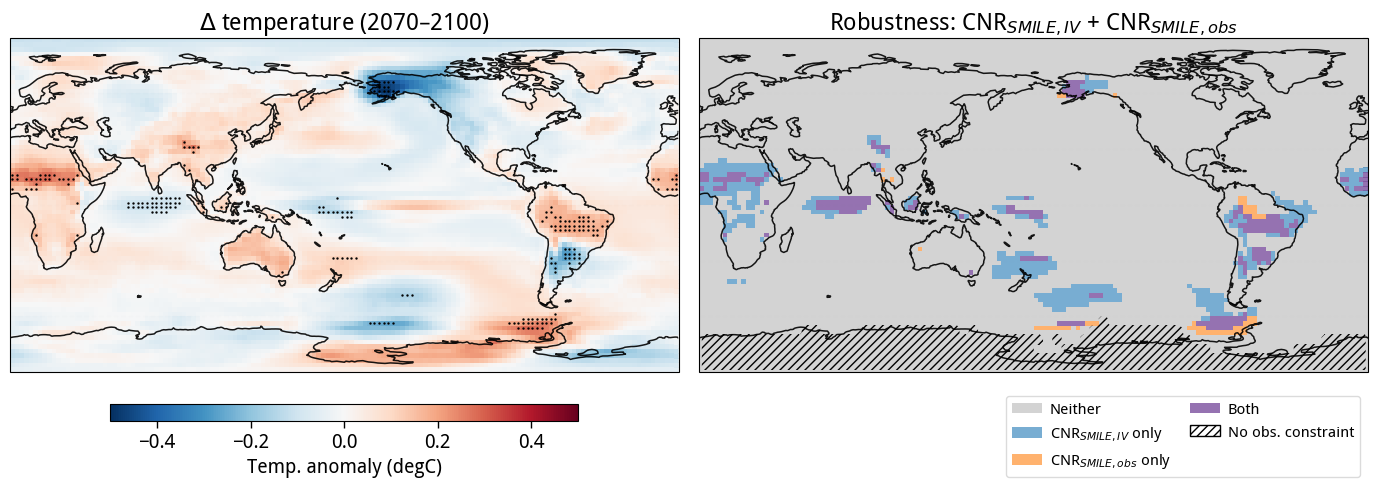

In [46]:
lon = tas_cmip6_regrid.lon.values
lat = tas_cmip6_regrid.lat.values

# --- EN TAS ---
# t-test only
plot_teleconnection_robustness(
    field        = signal_en_tas,
    lon=lon, lat=lat,
    pval_model   = pval_en_tas_ttest,
    use_pval     = True,
    cmap         = 'RdBu_r',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Temp. anomaly (degC)',
    title_main   = '$\Delta$ temperature (2070–2100)',
    title_suffix = 'Robustness (p < 0.05)'
)

# t-test + obs
plot_teleconnection_robustness(
    field        = signal_en_tas,
    lon=lon, lat=lat,
    pval_model   = pval_en_tas_ttest,
    snr_obs      = snr_en_tas_obs,
    use_pval     = True,
    valid_obs = valid_tas,
    cmap         = 'RdBu_r',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Temp. anomaly (degC)',
    title_main   = '$\Delta$ temperature (2070–2100)',
    title_suffix='Robustness: CMIP6 t-test + CNR$_{CMIP,obs}$',
    label_model='t-test only',
    label_obs='CNR$_{CMIP,obs}$ only',
)

# SMILE IV + obs
plot_teleconnection_robustness(
    field        = signal_en_tas,
    lon=lon, lat=lat,
    snr_model    = snr_en_tas_iv,
    snr_obs      = snr_en_tas_obs,
    use_pval     = False,
    valid_obs = valid_tas,
    cmap         = 'RdBu_r',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Temp. anomaly (degC)',
    title_main   = '$\Delta$ temperature (2070–2100)',
    title_suffix='Robustness: CNR$_{SMILE,IV}$ + CNR$_{SMILE,obs}$',
    label_model='CNR$_{SMILE,IV}$ only',
    label_obs='CNR$_{SMILE,obs}$ only',
)


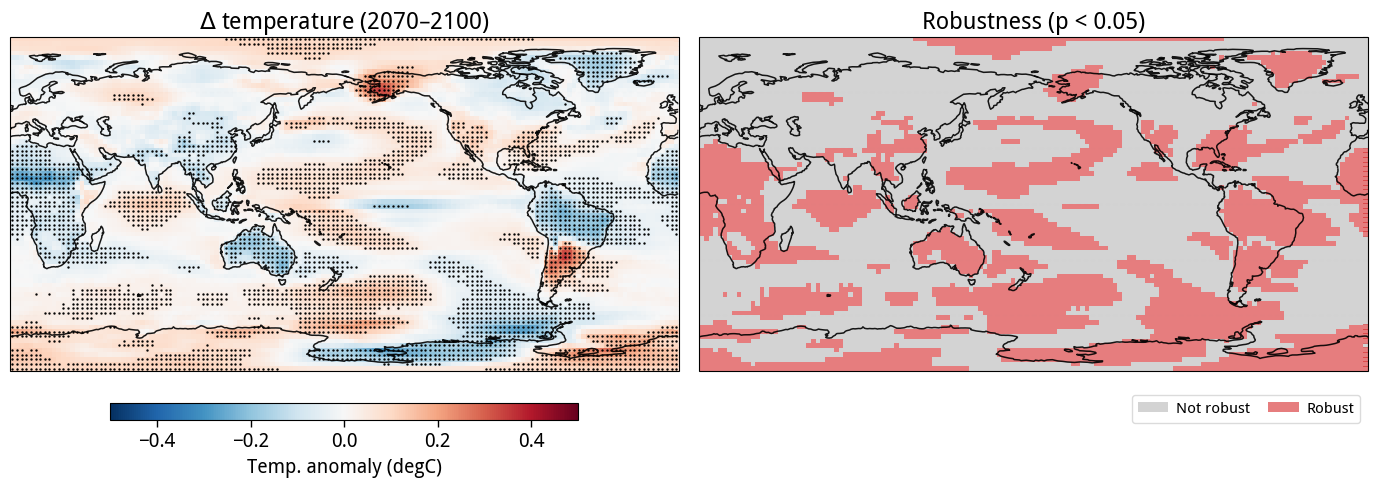

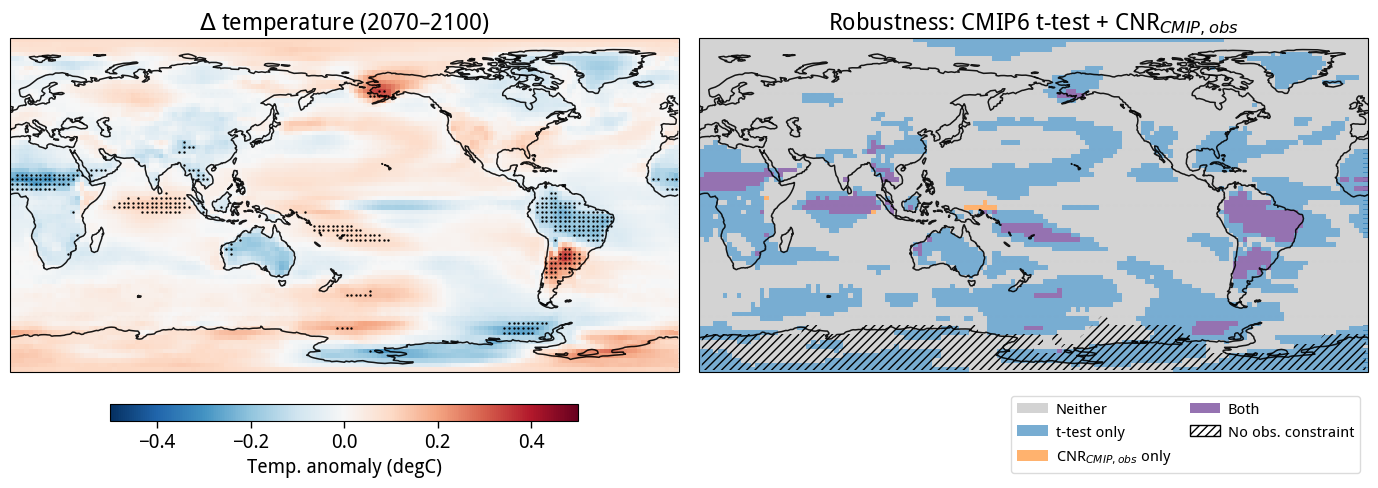

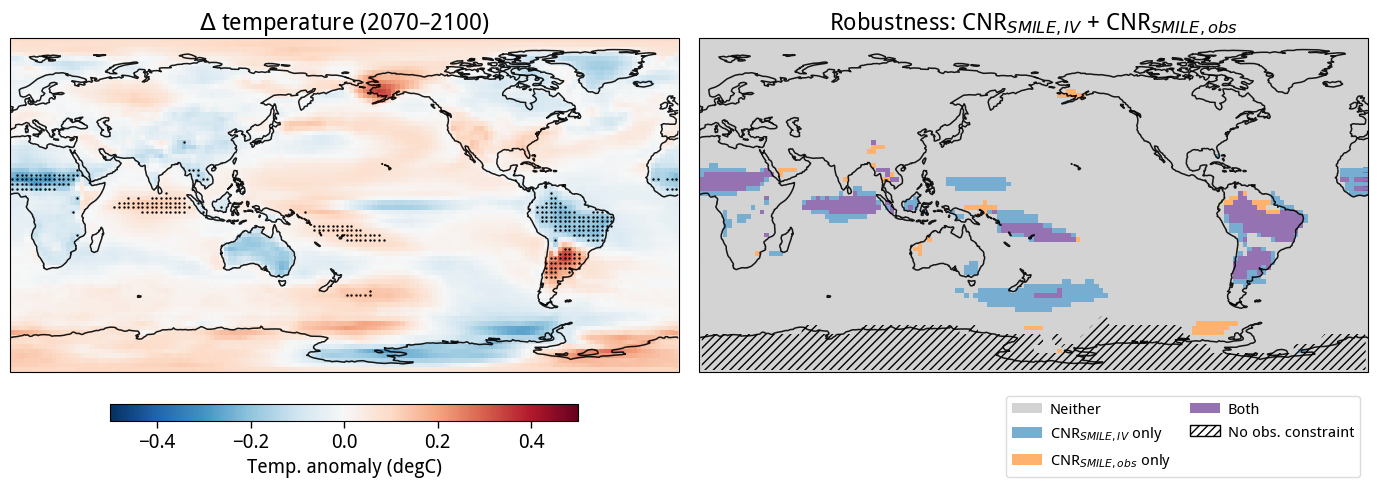

In [47]:
# --- ln TAS ---
# t-test only
plot_teleconnection_robustness(
    field        = signal_ln_tas,
    lon=lon, lat=lat,
    pval_model   = pval_ln_tas_ttest,
    use_pval     = True,
    cmap         = 'RdBu_r',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Temp. anomaly (degC)',
    title_main   = '$\Delta$ temperature (2070–2100)',
    title_suffix = 'Robustness (p < 0.05)'
)

# t-test + obs
plot_teleconnection_robustness(
    field        = signal_ln_tas,
    lon=lon, lat=lat,
    pval_model   = pval_ln_tas_ttest,
    snr_obs      = snr_ln_tas_obs,
    use_pval     = True,
    valid_obs = valid_tas,
    cmap         = 'RdBu_r',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Temp. anomaly (degC)',
    title_main   = '$\Delta$ temperature (2070–2100)',
    title_suffix='Robustness: CMIP6 t-test + CNR$_{CMIP,obs}$',
    label_model='t-test only',
    label_obs='CNR$_{CMIP,obs}$ only',
)

# SMILE IV + obs
plot_teleconnection_robustness(
    field        = signal_ln_tas,
    lon=lon, lat=lat,
    snr_model    = snr_ln_tas_iv,
    snr_obs      = snr_ln_tas_obs,
    use_pval     = False,
    valid_obs = valid_tas,
    cmap         = 'RdBu_r',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Temp. anomaly (degC)',
    title_main   = '$\Delta$ temperature (2070–2100)',
    title_suffix='Robustness: CNR$_{SMILE,IV}$ + CNR$_{SMILE,obs}$',
    label_model='CNR$_{SMILE,IV}$ only',
    label_obs='CNR$_{SMILE,obs}$ only',
)


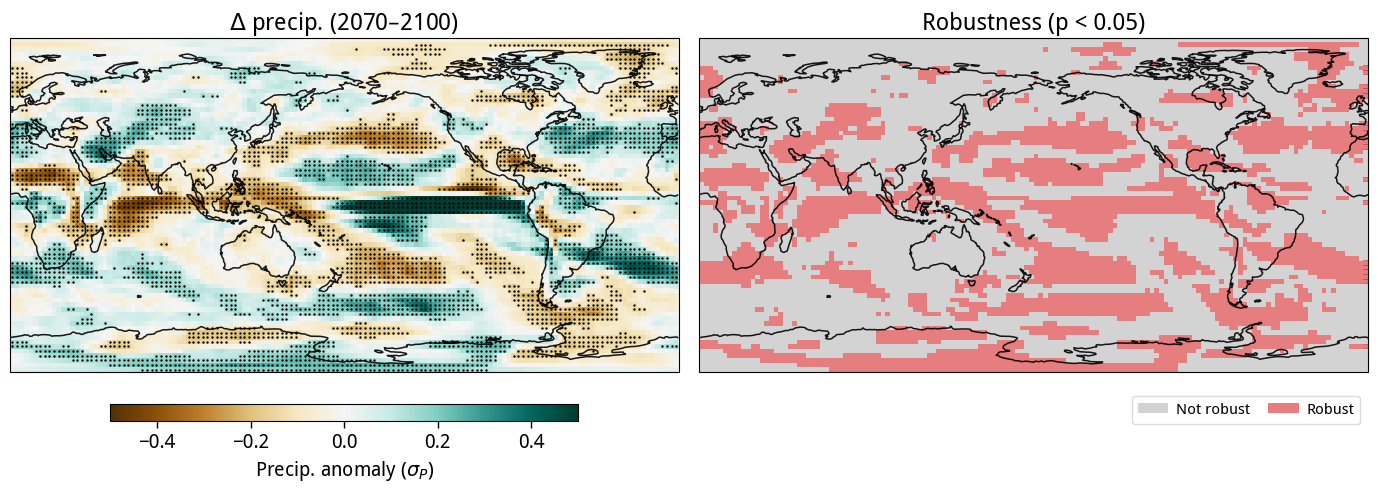

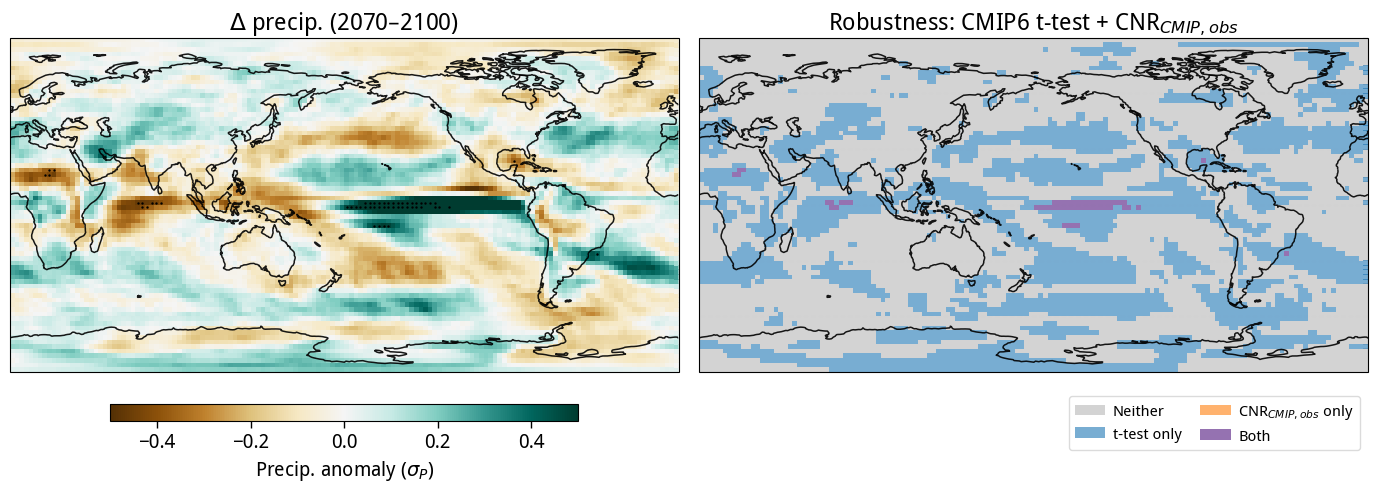

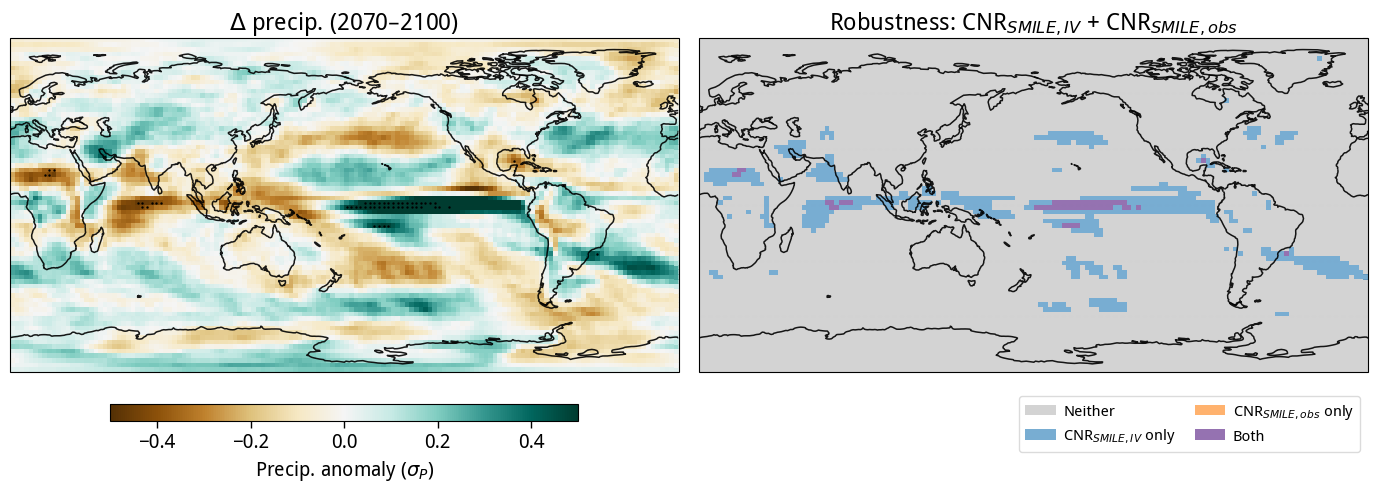

In [48]:
# --- EN PR ---
# t-test only
plot_teleconnection_robustness(
    field        = signal_en_pr,
    lon=lon, lat=lat,
    pval_model   = pval_en_pr_ttest,
    use_pval     = True,
    cmap         = 'BrBG',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Precip. anomaly ($\sigma_P$)',
    title_main   = '$\Delta$ precip. (2070–2100)',
    title_suffix = 'Robustness (p < 0.05)'
)

# t-test + obs
plot_teleconnection_robustness(
    field        = signal_en_pr,
    lon=lon, lat=lat,
    pval_model   = pval_en_pr_ttest,
    snr_obs      = snr_en_pr_obs,
    use_pval     = True,
    cmap         = 'BrBG',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Precip. anomaly ($\sigma_P$)',
    title_main   = '$\Delta$ precip. (2070–2100)',
    title_suffix='Robustness: CMIP6 t-test + CNR$_{CMIP,obs}$',
    label_model='t-test only',
    label_obs='CNR$_{CMIP,obs}$ only',
)

# SMILE IV + obs
plot_teleconnection_robustness(
    field        = signal_en_pr,
    lon=lon, lat=lat,
    snr_model    = snr_en_pr_iv,
    snr_obs      = snr_en_pr_obs,
    use_pval     = False,
    cmap         = 'BrBG',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Precip. anomaly ($\sigma_P$)',
    title_main   = '$\Delta$ precip. (2070–2100)',
    title_suffix='Robustness: CNR$_{SMILE,IV}$ + CNR$_{SMILE,obs}$',
    label_model='CNR$_{SMILE,IV}$ only',
    label_obs='CNR$_{SMILE,obs}$ only',
)


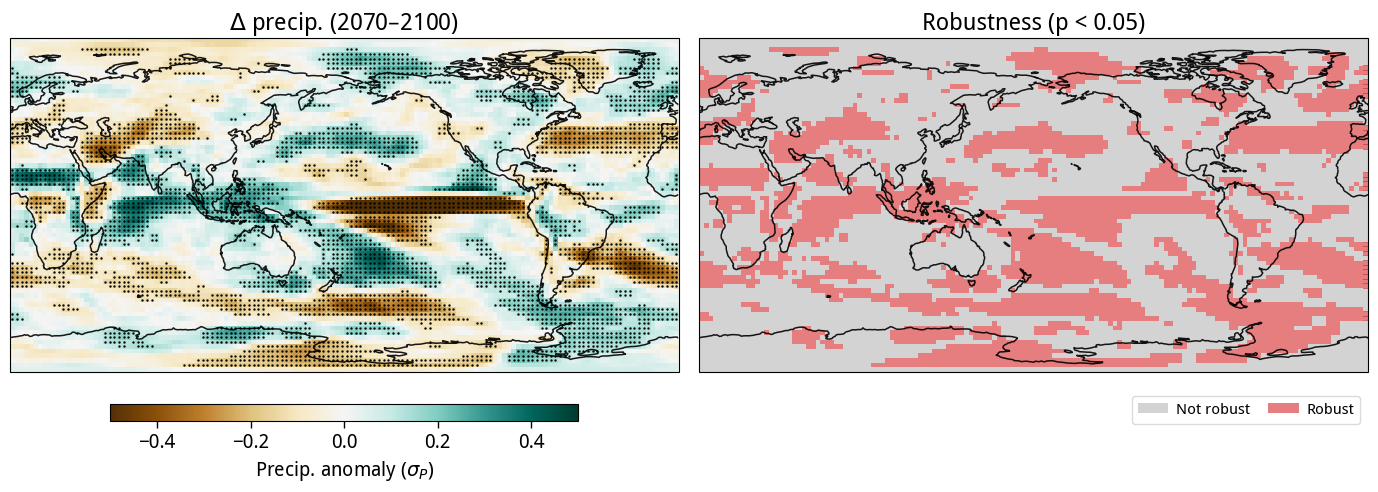

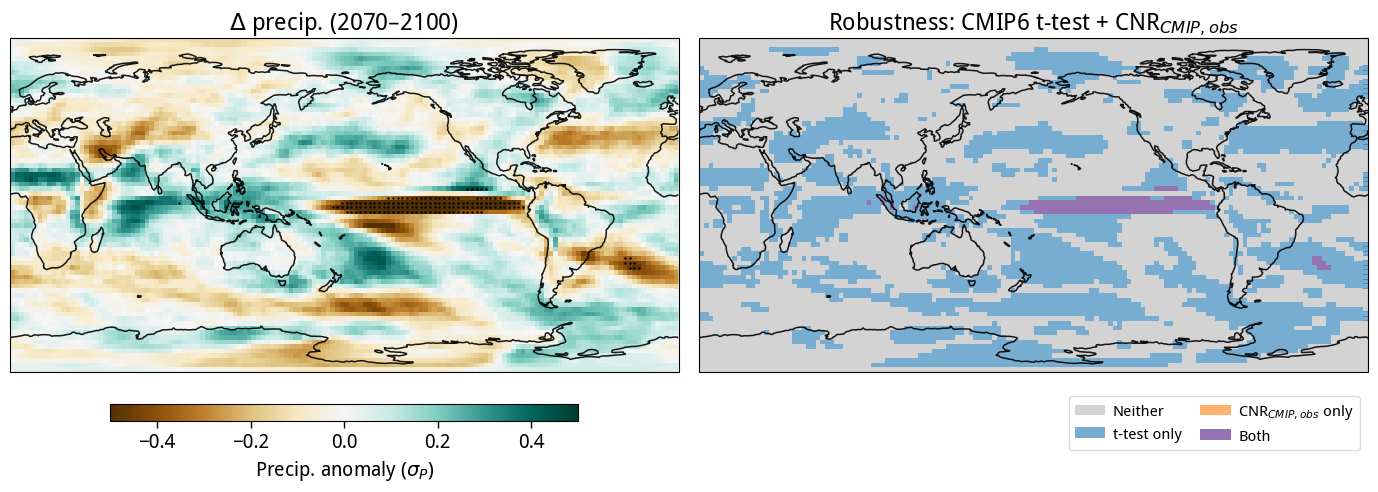

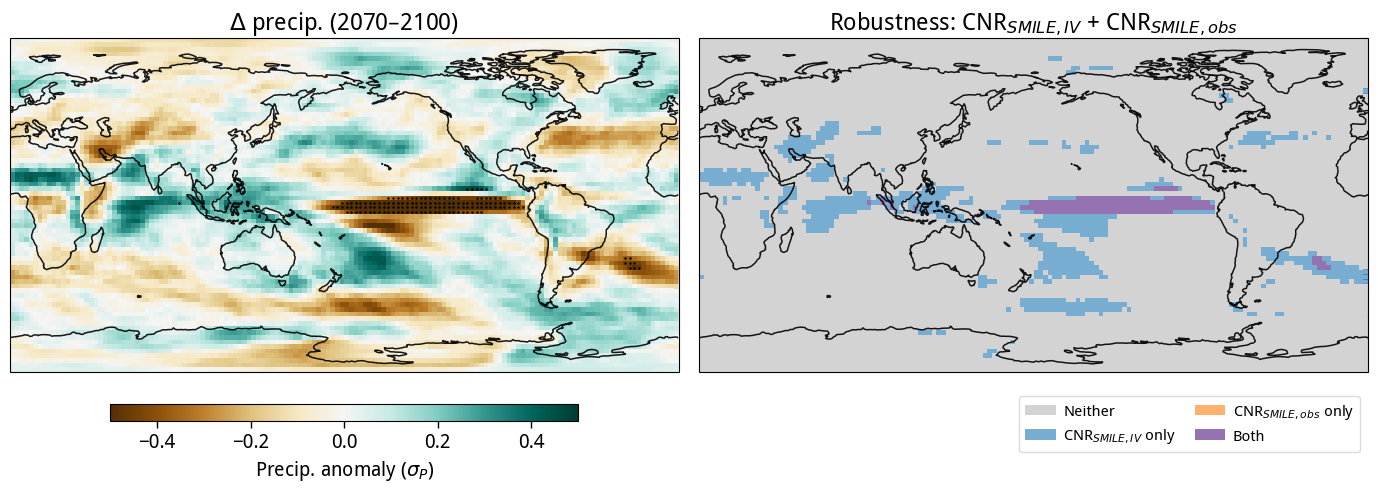

In [49]:
# --- ln PR ---
# t-test only
plot_teleconnection_robustness(
    field        = signal_ln_pr,
    lon=lon, lat=lat,
    pval_model   = pval_ln_pr_ttest,
    use_pval     = True,
    cmap         = 'BrBG',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Precip. anomaly ($\sigma_P$)',
    title_main   = '$\Delta$ precip. (2070–2100)',
    title_suffix = 'Robustness (p < 0.05)'
)

# t-test + obs
plot_teleconnection_robustness(
    field        = signal_ln_pr,
    lon=lon, lat=lat,
    pval_model   = pval_ln_pr_ttest,
    snr_obs      = snr_ln_pr_obs,
    use_pval     = True,
    cmap         = 'BrBG',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Precip. anomaly ($\sigma_P$)',
    title_main   = '$\Delta$ precip. (2070–2100)',
    title_suffix='Robustness: CMIP6 t-test + CNR$_{CMIP,obs}$',
    label_model='t-test only',
    label_obs='CNR$_{CMIP,obs}$ only',
)

# SMILE IV + obs
plot_teleconnection_robustness(
    field        = signal_ln_pr,
    lon=lon, lat=lat,
    snr_model    = snr_ln_pr_iv,
    snr_obs      = snr_ln_pr_obs,
    use_pval     = False,
    cmap         = 'BrBG',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'Precip. anomaly ($\sigma_P$)',
    title_main   = '$\Delta$ precip. (2070–2100)',
    title_suffix='Robustness: CNR$_{SMILE,IV}$ + CNR$_{SMILE,obs}$',
    label_model='CNR$_{SMILE,IV}$ only',
    label_obs='CNR$_{SMILE,obs}$ only',
)


In [50]:
def plot_enso_agreement(mask_en, mask_ln, lon, lat, title='',
                        valid_obs=None, label_noobs='No obs. constraint'):

    import matplotlib.colors as mcolors
    import numpy as np
    from matplotlib.patches import Patch

    xx, yy = np.meshgrid(lon, lat)

    # --- Valid-obs handling ---
    if valid_obs is not None:
        valid_v = valid_obs.values.astype(bool)
    else:
        valid_v = np.ones(xx.shape, dtype=bool)
    no_obs_v = ~valid_v

    fig, ax = plt.subplots(
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180)),
        figsize=(10, 4)
    )

    me = mask_en.values
    ml = mask_ln.values

    # --- Categories, only where obs is valid ---
    base     = np.where(~me & ~ml & valid_v, 1, np.nan)
    en_field = np.where( me &       valid_v, 1, np.nan)
    ln_field = np.where(       ml & valid_v, 1, np.nan)

    ax.pcolormesh(xx, yy, base,
                  cmap=mcolors.ListedColormap(['lightgrey']),
                  vmin=0, vmax=1,
                  transform=ccrs.PlateCarree())
    ax.pcolormesh(xx, yy, en_field,
                  cmap=mcolors.ListedColormap(['tab:red']),
                  vmin=0, vmax=1, alpha=0.6,
                  transform=ccrs.PlateCarree())
    ax.pcolormesh(xx, yy, ln_field,
                  cmap=mcolors.ListedColormap(['tab:blue']),
                  vmin=0, vmax=1, alpha=0.6,
                  transform=ccrs.PlateCarree())

    # --- Hatch overlay where obs test unavailable ---
    if no_obs_v.any():
        ax.contourf(xx, yy, no_obs_v.astype(float),
                    levels=[0.5, 1.5], colors='none',
                    hatches=['////'],
                    transform=ccrs.PlateCarree(), zorder=2)

    # --- Legend ---
    legend_elements = [
        Patch(facecolor='lightgrey',                  label='Neither'),
        Patch(facecolor='tab:red',   alpha=0.7,       label='EN only'),
        Patch(facecolor='tab:blue',  alpha=0.7,       label='LN only'),
        Patch(facecolor='mediumpurple', alpha=0.8,    label='Both'),
    ]
    if no_obs_v.any():
        legend_elements.append(
            Patch(facecolor='white', edgecolor='k', hatch='////',
                  label=label_noobs)
        )

    ax.legend(handles=legend_elements, loc='lower left',
              fontsize=11, framealpha=0.9)
    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()
    # return fig

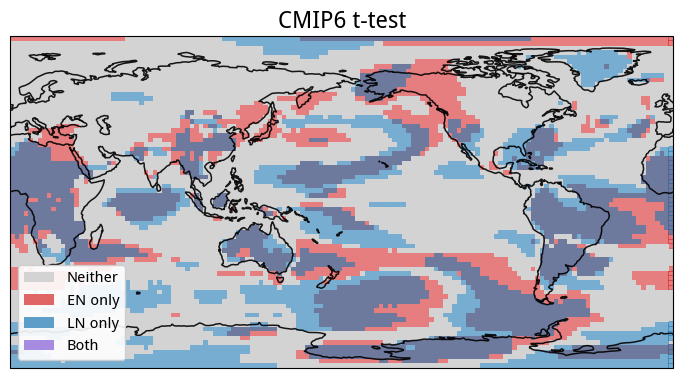

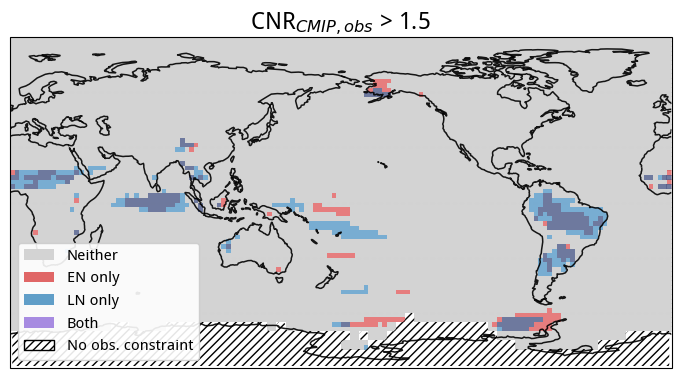

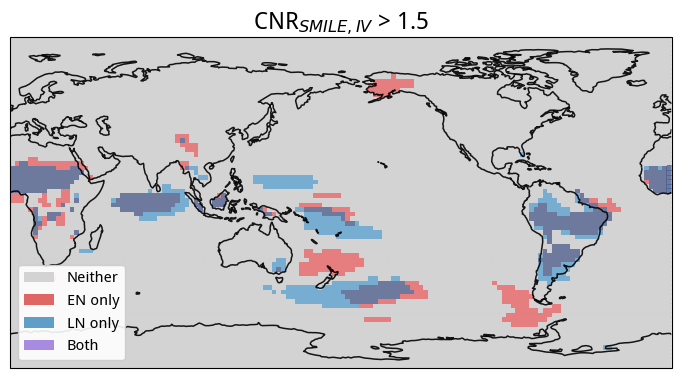

In [53]:
lon = tas_smile['ACCESS-ESM1-5'].lon.values
lat = tas_smile['ACCESS-ESM1-5'].lat.values

# --- TAS ---
# t-test only
plot_enso_agreement(mask_en_tas_ttest, mask_ln_tas_ttest, lon, lat,
                    title='CMIP6 t-test')

# obs S/N
plot_enso_agreement(mask_en_tas_obs, mask_ln_tas_obs, lon, lat, valid_obs = valid_tas,
                    title='CNR$_{CMIP,obs}$ > 1.5')

# SMILE IV
plot_enso_agreement(mask_en_tas_iv, mask_ln_tas_iv, lon, lat,
                    title='CNR$_{SMILE,IV}$ > 1.5')


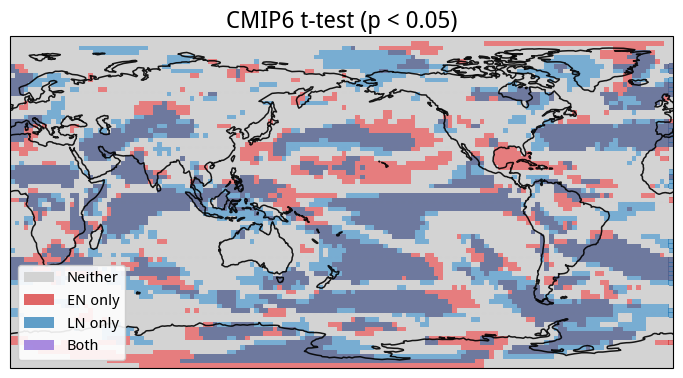

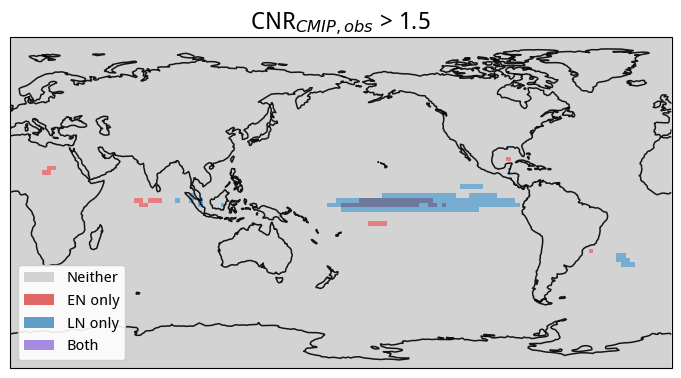

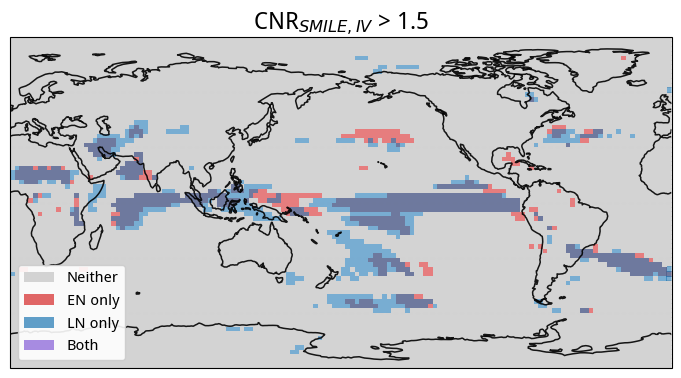

In [54]:
# --- PR ---
# t-test only
plot_enso_agreement(mask_en_pr_ttest, mask_ln_pr_ttest, lon, lat,
                    title='CMIP6 t-test (p < 0.05)')

# obs S/N
plot_enso_agreement(mask_en_pr_obs, mask_ln_pr_obs, lon, lat, valid_obs = valid_pr,
                    title='CNR$_{CMIP,obs}$ > 1.5')

# SMILE IV
plot_enso_agreement(mask_en_pr_iv, mask_ln_pr_iv, lon, lat,
                    title='CNR$_{SMILE,IV}$ > 1.5')